<a href="https://colab.research.google.com/github/Namtk214/AIO-Homework/blob/main/Face_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -U insightface

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 439.5/439.5 kB 8.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 34.6 MB/s eta 0:00:00
  Created wheel for insightface: filename=insightface-0.7.3-cp311-cp311-linux_x86_64.whl size=1060431 sha256=ab8de34962aabe011acccf3dc72365c17162c798102a714cafb560e51867785b
  Stored in directory: /root/.cache/pip/wheels/27/d8/22/f52d858d16cd06e7b2e6aad34a1777dcfaf000be833bbf8146
Successfully built insightface


In [5]:
!pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 92.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 8.0 MB/s eta 0:00:00


In [15]:
!pip install numpy==1.23.5


In [17]:
import cv2
import insightface
from insightface.app import FaceAnalysis
from insightface.data import get_image as ins_get_image
import numpy as np
if not hasattr(np, 'int'):
    np.int = int


# Method-1, use FaceAnalysis
app = FaceAnalysis(allowed_modules=['detection']) # enable detection model only
app.prepare(ctx_id=0, det_size=(640, 640))

# Method-2, load model directly
detector = insightface.model_zoo.get_model('/content/w600k_r50.onnx')
detector.prepare(ctx_id=0, input_size=(640, 640))


/usr/local/lib/python3.11/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:121: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/w600k_r50.onnx recognition
set det-size: (640, 640)
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}


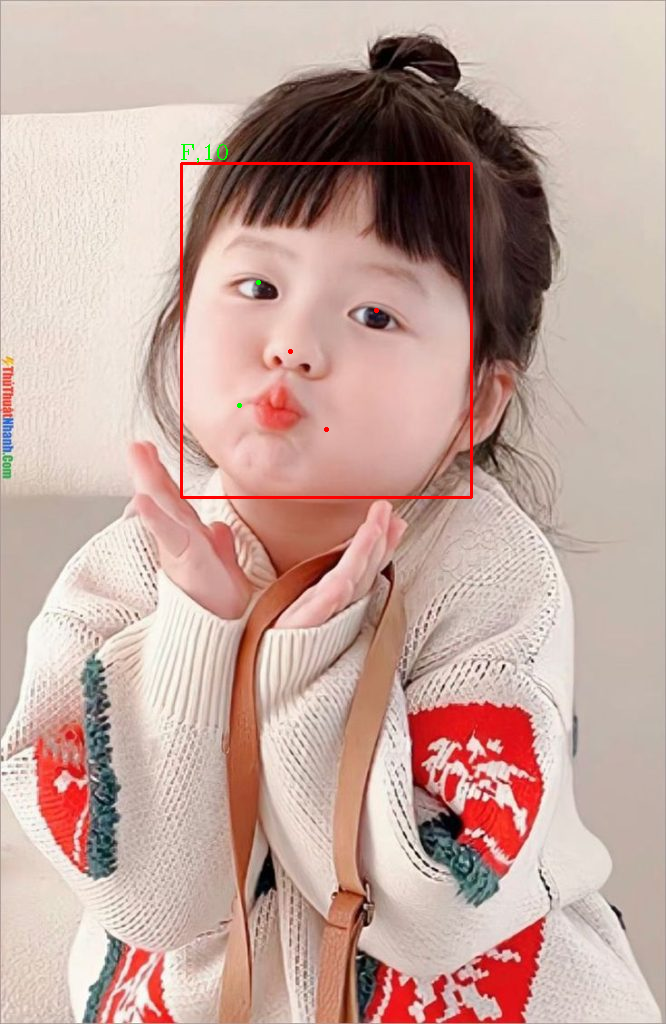

In [43]:
# Example using the FaceAnalysis app for detection
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import insightface
from insightface.app import FaceAnalysis

if not hasattr(np, 'int'):
    np.int = int

# --- Load your own image ---
# Upload your image to your Colab environment (e.g., by dragging and dropping into the file explorer)
# Then, replace the placeholder path below with the path to your image file.
image_path = '/content/example_2.jpg'  # Replace with the actual path to your image
img = cv2.imread(image_path)

if img is None:
    print(f"Error: Could not load image from {image_path}")
else:
    # --- Face Detection ---
    # Ensure the 'app' object for FaceAnalysis (with detection) is initialized from a previous cell
    # Example initialization (if not already done):
    # app = FaceAnalysis(allowed_modules=['detection'], providers=['CPUExecutionProvider'])
    # app.prepare(ctx_id=0, det_size=(640, 640))

    faces = app.get(img)

    # Draw bounding boxes on the image
    rimg = app.draw_on(img, faces)

    # Save the output image
    # cv2.imwrite("./output_image_with_faces.jpg", rimg)

    # Display the output image (optional, for Colab)
    cv2_imshow(rimg)

In [21]:
import cv2
import numpy as np
import insightface
from insightface.app import FaceAnalysis
from insightface.data import get_image as ins_get_image

# Khởi tạo FaceAnalysis để detect khuôn mặt
app = FaceAnalysis(providers=['CPUExecutionProvider'])  # Hoặc thêm CUDAExecutionProvider nếu GPU có sẵn
app.prepare(ctx_id=0, det_size=(640, 640))

# Load model nhận dạng (ArcFace)
rec_model = insightface.model_zoo.get_model('/content/w600k_r50.onnx')
rec_model.prepare(ctx_id=0)  # ctx_id = -1 nếu chỉ muốn CPU

# Load ảnh demo
img = ins_get_image('t1')
faces = app.get(img)

if len(faces) > 0:
    # Lấy face đầu tiên
    face = faces[0]

    # Crop ảnh từ bbox
    x1, y1, x2, y2 = face.bbox.astype(int)
    face_img = img[y1:y2, x1:x2]

    # Resize về đúng kích thước input của model
    face_img = cv2.resize(face_img, tuple(rec_model.input_size))

    # Lấy embedding
    embedding = rec_model.get_feat(face_img)

    print("Face embedding shape:", embedding.shape)
    print(embedding)
else:
    print("No face detected in the image.")


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)


/usr/local/lib/python3.11/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:121: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
Face embedding shape: (1, 512)
[[ 1.8619863  -2.2034266   1.2076201   2.2336414   1.0853204  -0.05808619
   1.1846825   1.181304    2.6948037   0.7215569  -1.379238    0.21202014
   1.0621021   0.74464285  1.1321155  -3.3525567  -0.3742751   1.7726532
  -2.077911    1.0805694  -0.46844393  2.1971285   1.1537544  -2.201537
   0.46689153  1.0387082   0.7444174  -0.721961    0.23486912 -0.69814754
   1.3750793  -0.89057285  0.4217695  -1.0189193  -1.4195234  -1.0390472
   0.52976644  0.10615033 -0.28526545  0.1445101  -3.0195014  -0.5183853
  -1.2501338  -0.49287596  1.2957956   1.1292317  -1.2992538  -0.90911055
   0.11491169 -0.08243615 -0.7843345   1.0066074   2.0788507  -1.668684
   1.6515701  -2.5740561   0.3608113  -0.95327526  0.4913445   0.2595377
  -0.95013446 -0.39424703  0.47154546 -0.36163804 -0.66784614  0.34586996
   1.1237242   0.9049774   0.7400416   2.2000415  -0.01494952 -1.3696238
  

**Reasoning**:
Define the table name, column names, and their corresponding SQLite data types as requested in the instructions.



In [22]:
# Define table and column details
table_name = "face_data"
id_column = "id"
image_column = "image"
vector_embed_column = "vector_embed"

# Define SQLite data types
id_type = "INTEGER PRIMARY KEY AUTOINCREMENT"
image_type = "TEXT"  # For Base64 encoded image data
vector_embed_type = "BLOB" # For binary embedding vector

print(f"Table Name: {table_name}")
print(f"Columns:")
print(f"  {id_column}: {id_type}")
print(f"  {image_column}: {image_type}")
print(f"  {vector_embed_column}: {vector_embed_type}")

Table Name: face_data
Columns:
  id: INTEGER PRIMARY KEY AUTOINCREMENT
  image: TEXT
  vector_embed: BLOB


In [23]:
import sqlite3

# Define the database name
database_name = "face_database.db"

# Connect to the database (creates the file if it doesn't exist)
conn = sqlite3.connect(database_name)

# Create a cursor object
cursor = conn.cursor()

# Define the SQL statement to create the table
create_table_sql = f"""
CREATE TABLE IF NOT EXISTS {table_name} (
    {id_column} {id_type},
    {image_column} {image_type},
    {vector_embed_column} {vector_embed_type}
);
"""

# Execute the SQL statement to create the table
cursor.execute(create_table_sql)

# Commit the changes
conn.commit()

# Close the connection
conn.close()

print(f"Database '{database_name}' and table '{table_name}' created successfully.")

Database 'face_database.db' and table 'face_data' created successfully.


In [24]:
import sqlite3
import base64

def insert_face_data(image_data_base64, vector_embedding):
    """
    Inserts face data (image and embedding) into the face_data table.

    Args:
        image_data_base64: Base64 encoded string of the image.
        vector_embedding: The vector embedding as bytes.
    """
    database_name = "face_database.db"
    table_name = "face_data"
    image_column = "image"
    vector_embed_column = "vector_embed"

    conn = None  # Initialize connection to None
    try:
        conn = sqlite3.connect(database_name)
        cursor = conn.cursor()

        insert_sql = f"""
        INSERT INTO {table_name} ({image_column}, {vector_embed_column})
        VALUES (?, ?);
        """

        cursor.execute(insert_sql, (image_data_base64, vector_embedding))

        conn.commit()
        print("Face data inserted successfully.")

    except sqlite3.Error as e:
        print(f"Database error: {e}")
    except Exception as e:
        print(f"An error occurred: {e}")
    finally:
        if conn:
            conn.close()

# Example usage (assuming you have an image and its embedding)
# Replace with your actual image data and embedding
# In a real scenario, you would load an image, encode it to Base64,
# and get the embedding using your face recognition model.

# Dummy data for demonstration
dummy_image_base64 = base64.b64encode(b"dummy image data").decode('utf-8')
dummy_embedding = b"\x01\x02\x03" * 170 # Dummy 510 byte data to simulate 512 dimensional float embedding

# Example: Convert the embedding from the previous cell (numpy array) to bytes
# Assuming 'embedding' from the previous cell is available and is a numpy array
# You would need to ensure the numpy array has a compatible data type and shape
# For a 512-dimensional float embedding, it might be float32 (4 bytes per float)
# Convert numpy array to bytes
# embedding_bytes = embedding.astype(np.float32).tobytes()

# insert_face_data(dummy_image_base64, dummy_embedding) # Uncomment to test with dummy data


In [30]:
import sqlite3

def retrieve_face_data(face_id=None):
    """
    Retrieves face data from the face_data table based on an optional ID.

    Args:
        face_id: Optional integer ID of the face data to retrieve.
                 If None, all face data will be retrieved.

    Returns:
        A list of tuples, where each tuple represents a row from the table.
        Each tuple contains (id, image_data_base64, vector_embedding_bytes).
        Returns an empty list if no data is found or an error occurs.
    """
    database_name = "face_database.db"
    table_name = "face_data"
    conn = None  # Initialize connection to None
    retrieved_data = []

    try:
        conn = sqlite3.connect(database_name)
        cursor = conn.cursor()

        select_sql = f"SELECT id, image, vector_embed FROM {table_name}"
        if face_id is not None:
            select_sql += " WHERE id = ?"
            cursor.execute(select_sql, (face_id,))
        else:
            cursor.execute(select_sql)

        retrieved_data = cursor.fetchall()
        print(f"Retrieved {len(retrieved_data)} rows.")

    except sqlite3.Error as e:
        print(f"Database error: {e}")
    except Exception as e:
        print(f"An error occurred: {e}")
    finally:
        if conn:
            conn.close()

    return retrieved_data


all_face_data = retrieve_face_data()
print("All face data:", all_face_data)


insert_face_data(base64.b64encode(b"dummy image 1").decode('utf-8'), b"\x01" * 512)
insert_face_data(base64.b64encode(b"dummy image 2").decode('utf-8'), b"\x02" * 512)


specific_face_data = retrieve_face_data(1)
print("Face data for ID 1:", specific_face_data)


Database error: database disk image is malformed
All face data: []
Database error: database disk image is malformed
Database error: database disk image is malformed
Database error: database disk image is malformed
Face data for ID 1: []


In [44]:
# Import necessary libraries
import cv2
import numpy as np
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode

# JavaScript to access the webcam and capture a single frame
def capture_photo():
  js = Javascript('''
    async function capturePhoto() {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for video to start playing
      await new Promise((resolve) => video.onplaying = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      return canvas.toDataURL('image/jpeg', 0.8);
    }
    ''')
  display(js)
  data = eval_js('capturePhoto()')
  return data

# Function to convert base64 data URL to OpenCV image
def data_url_to_image(data_url):
  encoded_image = data_url.split(',')[1]
  binary_image = b64decode(encoded_image)
  nparr = np.frombuffer(binary_image, np.uint8)
  img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
  return img

In [45]:
# This cell was part of a previous attempt at continuous streaming and is no longer needed
# for the single-frame capture approach.

In [ ]:
# Process a single captured frame for face detection

# Ensure the 'app' object for FaceAnalysis (with detection) is initialized from a previous cell
# Example initialization (if not already done):
# import insightface
# from insightface.app import FaceAnalysis
# app = FaceAnalysis(allowed_modules=['detection'], providers=['CPUExecutionProvider'])
# app.prepare(ctx_id=0, det_size=(640, 640))

# Capture a photo from the webcam
print("Capturing photo from webcam...")
image_data_url = capture_photo()
img = data_url_to_image(image_data_url)

# if image_data_url:
#     # Convert the data URL to an OpenCV image
#     img = data_url_to_image(image_data_url)

#     if img is not None:
#         print("Photo captured. Performing face detection...")
#         # Perform face detection using the 'app' object
#         if 'app' in globals(): # Check if app is initialized
#             try:
#                 faces = app.get(img)

#                 # Draw bounding boxes on the image
#                 rimg = app.draw_on(img.copy(), faces)

#                 # Display the processed frame
#                 from google.colab.patches import cv2_imshow
#                 cv2_imshow(rimg)

#                 # You can add logic here to process faces (e.g., get embeddings)
#                 if len(faces) > 0:
#                     print(f"Detected {len(faces)} face(s).")
#                 else:
#                     print("No face detected.")

#             except Exception as e:
#                 print(f"Error during face detection: {e}")
#         else:
#             print("FaceAnalysis app is not initialized. Please run the initialization cell.")
#     else:
#         print("Could not convert data URL to image.")
# else:
#     print("Failed to capture photo.")

In [52]:
img = data_url_to_image(image_data_url)

NameError: name 'image_data_url' is not defined

In [55]:
# requirements (cài 1 lần):
# pip install insightface onnxruntime opencv-python

import cv2
import time
import numpy as np
from insightface.app import FaceAnalysis

# --- Cấu hình ---
CAM_INDEX = 0            # 0 cho webcam mặc định; đổi nếu bạn có nhiều camera
TARGET_FPS = 10          # nhịp detect mong muốn (time-based throttling)
DET_SIZE = (640, 640)    # kích thước input cho detector (SCRFD)
DRAW_LANDMARKS = True

# --- Khởi tạo camera ---
# Using cv2.VideoCapture directly in Colab will not work as it cannot access your local webcam.
# The correct approach is to use Colab's JavaScript integration to capture frames.
# cap = cv2.VideoCapture(CAM_INDEX)
# (tùy camera mới/không mới mà set FPS/Resolution có thể không hiệu lực)
# cap.set(cv2.CAP_PROP_FRAME_WIDTH,  1280)
# cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
# cap.set(cv2.CAP_PROP_FPS, TARGET_FPS)  # nhiều device sẽ bỏ qua

# if not cap.isOpened():
#     raise RuntimeError("Không mở được camera. Hãy kiểm tra CAM_INDEX hoặc quyền truy cập.")

# --- Khởi tạo InsightFace: chỉ detection (SCRFD) ---
# Ensure the 'app' object for FaceAnalysis is initialized in a previous cell
# app = FaceAnalysis(allowed_modules=['detection'])
# ctx_id=0 cho CPU; nếu có GPU CUDA, dùng ctx_id=0 (InsightFace tự nhận), hoặc thử providers=['CUDAExecutionProvider']
# app.prepare(ctx_id=0, det_size=DET_SIZE)

# interval = 1.0 / TARGET_FPS
# last_t = 0.0

# print("Nhấn 'q' để thoát.")
# while True:
#     ok, frame = cap.read()
#     if not ok:
#         print("⚠️  Mất frame từ camera.")
#         break

#     now = time.time()
#     if now - last_t >= interval:
#         # BGR (OpenCV) -> dùng trực tiếp cho InsightFace
#         faces = app.get(frame)  # trả về list Face, có bbox + 5 landmarks

#         # Vẽ kết quả
#         vis = frame.copy()
#         for f in faces:
#             x1, y1, x2, y2 = f.bbox.astype(int)
#             cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)

#             if DRAW_LANDMARKS and hasattr(f, "landmark") and f.landmark is not None:
#                 for (lx, ly) in f.landmark.astype(int):
#                     cv2.circle(vis, (lx, ly), 2, (255, 0, 0), -1)

#             # điểm tin cậy detector
#             if hasattr(f, "det_score"):
#                 txt = f"{f.det_score:.2f}"
#                 cv2.putText(vis, txt, (x1, max(0, y1-5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

#         cv2.imshow("Face Detection - InsightFace (q to quit)", vis)
#         last_t = now
#     else:
#         # Hiển thị frame gốc giữa các lần detect (tùy chọn)
#         cv2.imshow("Face Detection - InsightFace (q to quit)", frame)

#     if cv2.waitKey(1) & 0xFF == ord('q'):
#         break

# cap.release()
# cv2.destroyAllWindows()

print("This cell was designed for direct camera access using cv2.VideoCapture, which does not work in Colab.")
print("Please use the other cells provided for webcam access using Colab's JavaScript integration.")

This cell was designed for direct camera access using cv2.VideoCapture, which does not work in Colab.
Please use the other cells provided for webcam access using Colab's JavaScript integration.
